# Previsor de Viralidade
### Machine Learning para estimar se um vídeo curto vai viralizar, a partir do gancho, da estrutura e do conteúdo

**Autor:** Gustavo Pugliezi · **Disciplina:** Computer Science · **Ferramentas:** Python, pandas, scikit-learn, matplotlib

---

| Passo | Etapa do framework | O que é feito aqui |
|---|---|---|
| [1](#p1) | Problema e label | definir o que é "viral" |
| [2](#p2) | Features mensuráveis | 11 características com regra de medição objetiva |
| [3](#p3) | Posts em JSON | carregar 3.000 posts |
| [4](#p4) | Extração das features | LLM ou simulação de sala de aula |
| [5](#p5) | Dataset | tabela final, exploração e engenharia de features |
| [6](#p6) | `X` e `y` | separar features e label |
| [7](#p7) | Treino e teste | divisão 80/20 |
| [8](#p8) | Regressão Logística | treinar o modelo |
| [9](#p9) | Avaliação | acurácia e matriz de confusão |
| [10](#p10) | Dados novos | prever posts que nunca existiram no dataset |
| [11](#p11) | Exportar `.pkl` | salvar o modelo treinado |
| [12](#p12) | Rodar em outra aplicação | abrir o `.pkl` fora do notebook |

**Arquivos do projeto**
```
data/posts.json          ← posts recebidos (passo 3)
data/posts_novos.json    ← posts novos, sem resposta (passo 10)
data/dataset.csv         ← dataset gerado (passo 5)
app/viralidade.py        ← funções de extração e engenharia de features
app/prever.py            ← aplicação que usa o .pkl (passo 12)
modelo/previsor_viral.pkl← modelo treinado (passo 11)
site/                    ← site da apresentação
```

In [1]:
import sys, json, pickle, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, display

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

sys.path.insert(0, "../app")
import viralidade as vz          # módulo do projeto (extração + engenharia de features)

SEED = 42                       # deixa todos os sorteios reproduzíveis

TINTA, PAPEL, SINAL, CINZA = "#15171c", "#f8f9f6", "#e8341c", "#8a8f96"
plt.rcParams.update({"figure.facecolor": PAPEL, "axes.facecolor": PAPEL, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "figure.dpi": 110})
mostrar = lambda f: display(Code(inspect.getsource(f), language="python"))
print("Ambiente pronto.")

Ambiente pronto.


<a id="p1"></a>
## Passo 1 — Problema e label

**Problema:** um criador quer saber, **antes de postar**, se o vídeo tem chance de viralizar.

**Tipo de problema:** classificação binária supervisionada. Cada exemplo de treino já vem com a resposta certa.

**Label (`y`):** precisa ser objetiva e medível. Usamos o tamanho do perfil como referência, para que um perfil grande não pareça "viral" só por ser grande:

$$
\text{viral} = \begin{cases} 1 & \text{se } \text{views} \ge 10 \times \text{seguidores} \\ 0 & \text{caso contrário} \end{cases}
$$

> Exemplo: um perfil com 5.000 seguidores precisa de pelo menos 50.000 views para o vídeo contar como viral.

In [2]:
MULTIPLICADOR_VIRAL = 10

def calcular_label(post):
    return int(post["views"] >= MULTIPLICADOR_VIRAL * post["seguidores"])

<a id="p2"></a>
## Passo 2 — Features mensuráveis

Uma feature só serve se **duas pessoas diferentes, medindo o mesmo vídeo, chegarem ao mesmo valor**. Por isso cada uma tem uma regra de medição. Organizamos em três grupos:

| Grupo | Feature | Tipo | Regra de medição |
|---|---|---|---|
| **Hook** | `hook_segundos` | número | segundo da primeira frase de gancho na transcrição (sem gancho = 8) |
| | `tipo_hook` | categoria | pergunta, choque, promessa, história ou nenhum |
| | `rosto_1s` | 0/1 | aparece um rosto no primeiro segundo |
| | `texto_na_tela` | 0/1 | há texto escrito na tela no início |
| **Estrutura** | `duracao_seg` | número | duração em segundos |
| | `cortes_por_10s` | número | (nº de cortes ÷ duração) × 10 |
| | `estrutura` | categoria | lista, tutorial, antes/depois, storytime ou vlog |
| | `tem_loop` | 0/1 | o final emenda no começo |
| **Conteúdo** | `tema` | categoria | humor, educação, beleza, games, culinária, esporte |
| | `audio_em_alta` | 0/1 | usa áudio em alta |
| | `hora_postagem` | 0–23 | hora da postagem |

A mesma especificação está no código e é enviada ao LLM no passo 4:

In [3]:
pd.DataFrame.from_dict(vz.ESPEC_FEATURES, orient="index", columns=["regra de medição"])

,regra de medição
hook_segundos,número: segundo (timestamp da transcrição) da ...
tipo_hook,"texto, um de: pergunta, choque, promessa, hist..."
rosto_1s,0 ou 1: aparece um rosto no primeiro segundo?
texto_na_tela,0 ou 1: há texto escrito na tela no início?
duracao_seg,número: duração do vídeo em segundos
cortes_por_10s,"número: (número de cortes ÷ duração) × 10, com..."
estrutura,"texto, um de: lista, tutorial, antes_depois, s..."
tem_loop,0 ou 1: o final emenda no começo?
tema,"texto, um de: humor, educacao, beleza, games, ..."
audio_em_alta,0 ou 1: usa um áudio que está em alta?


<a id="p3"></a>
## Passo 3 — Recebendo os posts em JSON

Cada post tem os campos que uma plataforma ou um anotador forneceria: legenda, transcrição com tempo, notas visuais, duração e data. `views` e `seguidores` servem **apenas** para calcular a label.

> **Sobre os dados:** plataformas não informam coisas como "segundos até o gancho". Os 3.000 posts foram gerados pelo script `data/gerar_posts.py`, que segue regras inspiradas no que criadores observam e inclui um fator de sorte. O notebook não conhece essas regras; ele só lê o JSON.

In [4]:
with open("../data/posts.json", encoding="utf-8") as f:
    posts = json.load(f)

print(f"{len(posts)} posts carregados. Campos: {list(posts[0])}\n")
print(json.dumps(posts[0], ensure_ascii=False, indent=2))

3000 posts carregados. Campos: ['id', 'plataforma', 'legenda', 'transcricao', 'notas_visuais', 'duracao_seg', 'postado_em', 'seguidores', 'views']

{
  "id": "post_0001",
  "plataforma": "shorts",
  "legenda": "Meu dia com pão de queijo de frigideira #receita #culinaria",
  "transcricao": "[00:00.8] Olha o que aconteceu com pão de queijo de frigideira\n[00:06.1] Pois é.\n[00:09.0] Pois é.",
  "notas_visuais": "começa mostrando o cenário; legenda escrita em cima do vídeo; som viral do momento; edição com 20 cortes",
  "duracao_seg": 52,
  "postado_em": "2026-01-18T18:09",
  "seguidores": 32159,
  "views": 37741
}


<a id="p4"></a>
## Passo 4 — Extraindo os valores das features

Os posts são **texto**. O modelo precisa de **números e categorias**. Alguém precisa ler cada post e preencher as 11 features. Há dois caminhos:

| | 4a. LLM | 4b. Simulação de sala de aula |
|---|---|---|
| Como funciona | envia o post e a especificação do passo 2 para um modelo de linguagem, que devolve um JSON | regras de palavras-chave aplicadas aos mesmos textos |
| Precisa de | internet e `ANTHROPIC_API_KEY` | nada |
| Vantagem | entende textos variados | rápido, gratuito, reproduzível |

> **Cuidado com vazamento de dados:** a função só envia os campos de `vz.CAMPOS_VISIVEIS`. `views` e `seguidores` **nunca** são mostrados a quem extrai as features, senão a resposta estaria "escondida" dentro das perguntas.

### 4a. Extração com LLM

In [5]:
mostrar(vz.extrair_com_llm)

def extrair_com_llm(post, modelo="claude-haiku-5-5"):
    import anthropic
    cliente = anthropic.Anthropic()
    visivel = {k: post[k] for k in CAMPOS_VISIVEIS if k in post}
    prompt = (
        "Você é um anotador de vídeos curtos. Leia o post abaixo e meça cada feature "
        "seguindo exatamente as regras. Responda SOMENTE com um objeto JSON com estas chaves:\n"
        + json.dumps(ESPEC_FEATURES, ensure_ascii=False, indent=1)
        + "\n\nPOST:\n" + json.dumps(visivel, ensure_ascii=False, indent=1)
    )
    resposta = cliente.messages.create(model=modelo, max_tokens=500,
                                       messages=[{"role": "user", "content": prompt}])
    texto = resposta.content[0].text
    return json.loads(texto[texto.find("{"): texto.rfind("}") + 1])

### 4b. Extração simulada
Lê a transcrição linha por linha procurando a primeira frase de gancho, e procura palavras-chave na legenda e nas notas visuais.

In [6]:
mostrar(vz.extrair_simulado)

def extrair_simulado(post):
    notas = post["notas_visuais"].lower()
    dur = float(post["duracao_seg"])

    # gancho: percorre a transcrição linha a linha, "[00:01.2] frase"
    tipo, segundos = "nenhum", 8.0
    for linha in post["transcricao"].split("\n"):
        m = re.match(r"\[(\d+):(\d+\.\d)\]\s*(.*)", linha)
        if not m:
            continue
        achou = _primeiro(PADROES_HOOK, m.group(3), None)
        if achou:
            tipo, segundos = achou, int(m.group(1)) * 60 + float(m.group(2))
            break

    cortes = re.search(r"(\d+) cortes", notas)
    return {
        "hook_segundos": segundos,
        "tipo_hook": tipo,
        "rosto_1s": int(bool(re.search(r"close no rosto|rosto aparece", notas))),
        "texto_na_tela": int(bool(re.search(r"texto grande|legenda escrita", notas))),
        "duracao_seg": dur,
        "cortes_por_10s": round(int(cortes.group(1)) / dur * 10, 1) if cortes else 0.0,
        "estrutura": _primeiro(PADROES_ESTRUTURA, post["legenda"], "vlog"),
        "tem_loop": int(bool(re.search(r"emenda no começo|mesma cena do início", notas))),
        "tema": _primeiro(PADROES_TEMA, post["legenda"], "humor"),
        "audio_em_alta": int(bool(re.search(r"áudio em alta|som viral", notas))),
        "hora_postagem": datetime.fromisoformat(post["postado_em"]).hour,
    }

In [7]:
import os
USAR_LLM = False   # troque para True para usar o LLM (precisa de ANTHROPIC_API_KEY)
extrair = vz.extrair_com_llm if USAR_LLM else vz.extrair_simulado

print("Método:", "LLM" if USAR_LLM else "simulação de sala de aula")
print("\nPost:", posts[0]["legenda"])
print("Features extraídas:", extrair(posts[0]))

Método: simulação de sala de aula

Post: Meu dia com pão de queijo de frigideira #receita #culinaria
Features extraídas: {'hook_segundos': 0.8, 'tipo_hook': 'historia', 'rosto_1s': 0, 'texto_na_tela': 1, 'duracao_seg': 52.0, 'cortes_por_10s': 3.8, 'estrutura': 'vlog', 'tem_loop': 0, 'tema': 'culinaria', 'audio_em_alta': 1, 'hora_postagem': 18}


<a id="p5"></a>
## Passo 5 — Construindo o dataset

Aplicamos a extração em todos os posts e juntamos a label. Cada linha passa a ser um vídeo, cada coluna uma feature.

In [8]:
linhas = []
for post in posts:
    linha = {"id": post["id"], **extrair(post), "viral": calcular_label(post)}
    linhas.append(linha)

dataset = pd.DataFrame(linhas)
dataset.to_csv("../data/dataset.csv", index=False)
print(f"Dataset: {dataset.shape[0]} linhas × {dataset.shape[1]} colunas  →  data/dataset.csv")
print("Valores faltando:", int(dataset.isna().sum().sum()))
dataset.head()

Dataset: 3000 linhas × 13 colunas  →  data/dataset.csv
Valores faltando: 0


,id,hook_segundos,tipo_hook,rosto_1s,texto_na_tela,duracao_seg,cortes_por_10s,estrutura,tem_loop,tema,audio_em_alta,hora_postagem,viral
0,post_0001,0.8,historia,0,1,52.0,3.8,vlog,0,culinaria,1,18,0
1,post_0002,8.0,nenhum,1,1,38.0,7.6,antes_depois,1,humor,0,22,0
2,post_0003,1.1,choque,1,1,29.0,6.6,storytime,1,culinaria,1,4,1
3,post_0004,1.5,choque,1,1,55.0,2.7,vlog,1,esporte,1,20,1
4,post_0005,2.8,pergunta,1,1,65.0,7.7,storytime,0,esporte,1,2,0


### 5.1 Exploração dos dados

Virais: 739 de 3000  →  24.6%


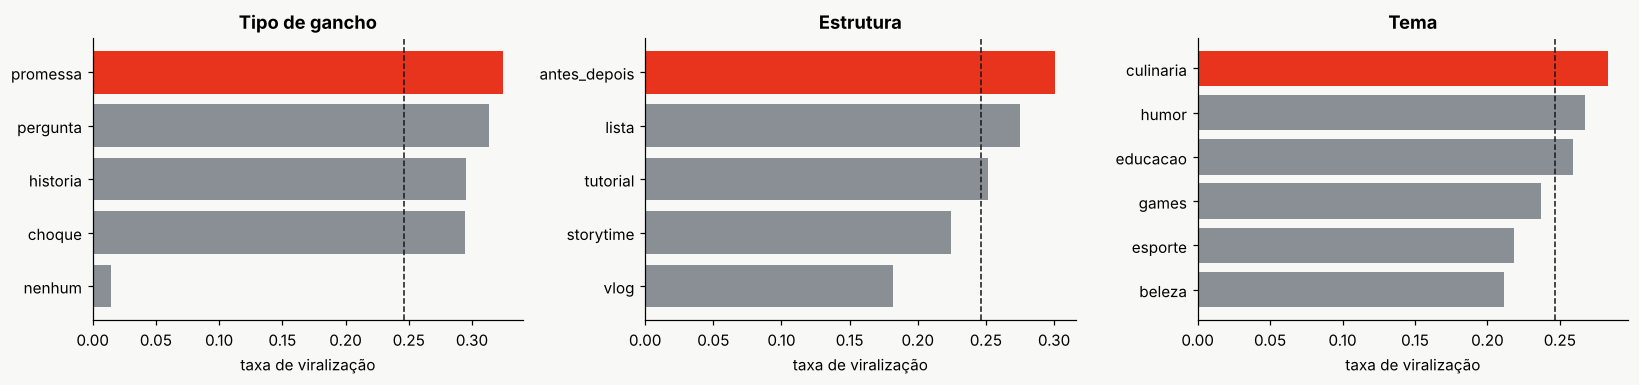

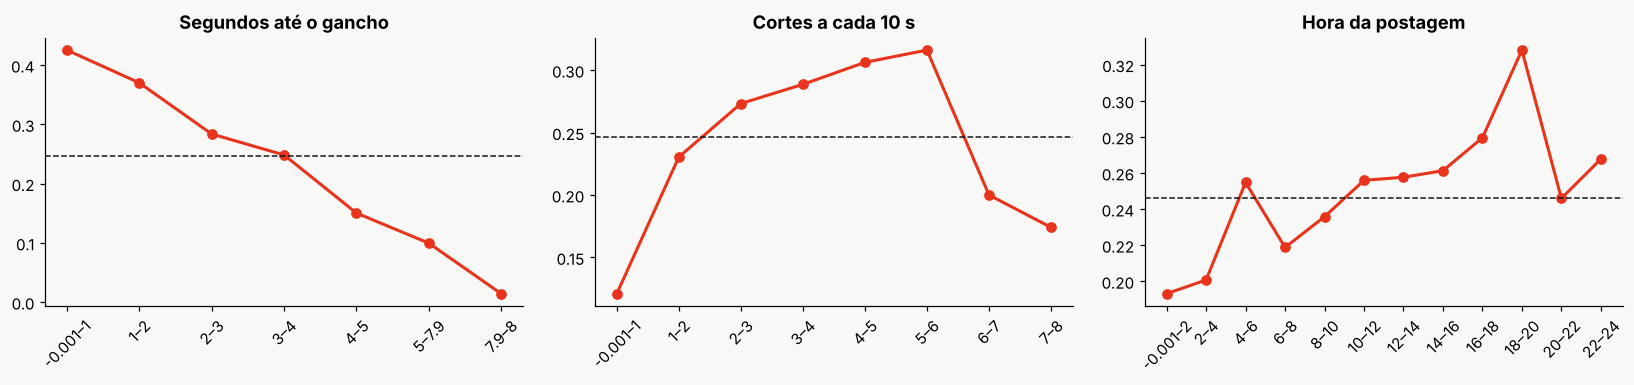

In [9]:
taxa = dataset.viral.mean()
print(f"Virais: {dataset.viral.sum()} de {len(dataset)}  →  {taxa:.1%}")

def taxa_por(coluna, ax, titulo):
    t = dataset.groupby(coluna).viral.mean().sort_values()
    ax.barh(t.index.astype(str), t.values, color=[SINAL if v == t.max() else CINZA for v in t])
    ax.axvline(taxa, color=TINTA, ls="--", lw=1); ax.set_title(titulo); ax.set_xlabel("taxa de viralização")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
taxa_por("tipo_hook", axes[0], "Tipo de gancho"); taxa_por("estrutura", axes[1], "Estrutura"); taxa_por("tema", axes[2], "Tema")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, bins, titulo in [(axes[0], "hook_segundos", [0, 1, 2, 3, 4, 5, 7.9, 8], "Segundos até o gancho"),
                              (axes[1], "cortes_por_10s", np.arange(0, 9, 1), "Cortes a cada 10 s"),
                              (axes[2], "hora_postagem", np.arange(0, 25, 2), "Hora da postagem")]:
    t = dataset.groupby(pd.cut(dataset[col], bins, include_lowest=True), observed=True).viral.mean()
    ax.plot(range(len(t)), t.values, marker="o", color=SINAL, lw=2)
    ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{i.left:g}–{i.right:g}" for i in t.index], rotation=45)
    ax.axhline(taxa, color=TINTA, ls="--", lw=1); ax.set_title(titulo)
plt.tight_layout(); plt.show()

**Observações**
- Só cerca de 1 em cada 4 vídeos viraliza. As classes são **desbalanceadas**: um modelo que sempre responde "não viral" já acertaria uns 75%. Por isso a acurácia será comparada com essa linha de base.
- Quanto mais o gancho demora, menor a chance. Vídeos sem gancho (8 s) são os piores.
- Os cortes formam um **U invertido**, com pico perto de 4 a cada 10 s.
- A hora tem um **degrau** no começo da noite (18h–22h).

### 5.2 Engenharia de features
A Regressão Logística só representa relações do tipo "mais X → mais chance". Para o U invertido e o degrau, transformamos as colunas:

| Nova coluna | Fórmula | Motivo |
|---|---|---|
| `ritmo_fora_do_ideal` | \|cortes − 4\| | o U vira linha reta |
| `horario_nobre` | 1 se 18 ≤ hora ≤ 22 | o degrau vira sim/não |
| `excesso_duracao` | máx(duração − 30, 0) | só os segundos além de 30 contam |

Os valores 4 e 30 foram tirados dos gráficos acima. A função fica no módulo para poder ser usada dentro do `.pkl`:

In [10]:
mostrar(vz.criar_features)
vz.criar_features(dataset.head(3))

def criar_features(d):
    """Transforma as 11 features medidas nas colunas que o modelo usa."""
    d = pd.DataFrame(d).copy()
    d["ritmo_fora_do_ideal"] = (d["cortes_por_10s"] - 4).abs()          # U invertido -> linha reta
    d["horario_nobre"] = d["hora_postagem"].between(18, 22).astype(int)  # degrau -> sim/não
    d["excesso_duracao"] = (d["duracao_seg"] - 30).clip(lower=0)         # só conta o que passa de 30 s
    return d[NUMERICAS + BINARIAS + CATEGORICAS]

,hook_segundos,excesso_duracao,ritmo_fora_do_ideal,rosto_1s,texto_na_tela,tem_loop,audio_em_alta,horario_nobre,tipo_hook,estrutura,tema
0,0.8,22.0,0.2,0,1,0,1,1,historia,vlog,culinaria
1,8.0,8.0,3.6,1,1,1,0,1,nenhum,antes_depois,humor
2,1.1,0.0,2.6,1,1,1,1,0,choque,storytime,culinaria


<a id="p6"></a>
## Passo 6 — Separando `X` e `y`

- **`X`** = as perguntas: as 11 features medidas.
- **`y`** = a resposta: a label `viral`.

A coluna `id` fica de fora: é só um nome, não diz nada sobre o vídeo.

In [11]:
X = dataset[vz.COLUNAS]
y = dataset["viral"]
print("X:", X.shape, "  y:", y.shape)
X.head(3)

X: (3000, 11)   y: (3000,)


,hook_segundos,tipo_hook,rosto_1s,texto_na_tela,duracao_seg,cortes_por_10s,estrutura,tem_loop,tema,audio_em_alta,hora_postagem
0,0.8,historia,0,1,52.0,3.8,vlog,0,culinaria,1,18
1,8.0,nenhum,1,1,38.0,7.6,antes_depois,1,humor,0,22
2,1.1,choque,1,1,29.0,6.6,storytime,1,culinaria,1,4


<a id="p7"></a>
## Passo 7 — Treino e teste

- **Treino (80%)**: o modelo aprende com estes vídeos.
- **Teste (20%)**: ficam separados e só são usados na avaliação. Medir com os mesmos vídeos do treino daria uma nota falsa, como fazer uma prova já conhecendo as questões.

`stratify=y` mantém a mesma proporção de virais nos dois grupos.

In [12]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Treino: {len(X_treino)} vídeos ({y_treino.mean():.1%} virais)")
print(f"Teste:  {len(X_teste)} vídeos ({y_teste.mean():.1%} virais)")

Treino: 2400 vídeos (24.6% virais)
Teste:  600 vídeos (24.7% virais)


<a id="p8"></a>
## Passo 8 — Treinando a Regressão Logística

O modelo é montado como um **Pipeline**, uma linha de montagem com três estações aplicadas sempre na mesma ordem:

| Estação | O que faz |
|---|---|
| `features` | engenharia de features do passo 5.2 |
| `preparo` | **StandardScaler** nos números (média 0, desvio 1) e **One-Hot** nas categorias (uma coluna 0/1 por opção) |
| `modelo` | **Regressão Logística**: aprende um peso por coluna; `chance = sigmoide(b + w₁x₁ + … + wₙxₙ)` |

Usar o Pipeline garante que o modelo salvo no passo 11 faça **exatamente** o mesmo preparo com dados novos.

In [13]:
def montar_pipeline(modelo):
    preparo = ColumnTransformer([
        ("num", StandardScaler(), vz.NUMERICAS),
        ("bin", "passthrough", vz.BINARIAS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), vz.CATEGORICAS),
    ])
    return Pipeline([
        ("features", FunctionTransformer(vz.criar_features)),
        ("preparo", preparo),
        ("modelo", modelo),
    ])

pipeline = montar_pipeline(LogisticRegression(max_iter=1000))
pipeline.fit(X_treino, y_treino)          # ← treino

lr = pipeline.named_steps["modelo"]
nomes = pipeline.named_steps["preparo"].get_feature_names_out()
print(f"Modelo treinado: {len(nomes)} pesos + 1 intercepto (b = {lr.intercept_[0]:.2f})")

Modelo treinado: 24 pesos + 1 intercepto (b = -2.32)


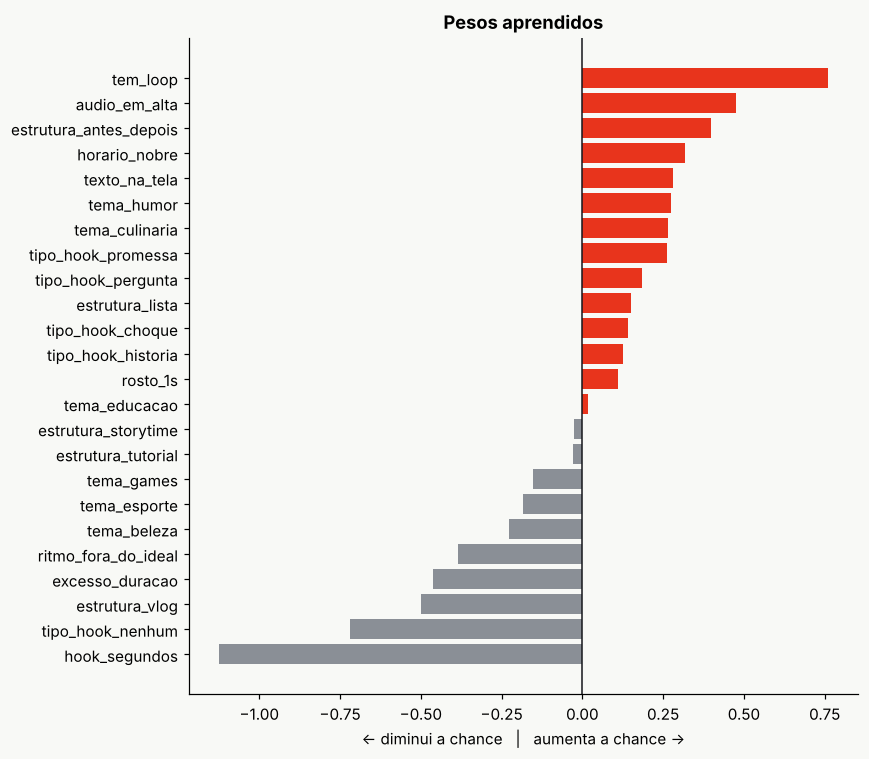

In [14]:
pesos = pd.Series(lr.coef_[0], index=[n.split("__")[1] for n in nomes]).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(pesos.index, pesos.values, color=[SINAL if v > 0 else CINZA for v in pesos.values])
ax.axvline(0, color=TINTA, lw=1)
ax.set_title("Pesos aprendidos"); ax.set_xlabel("← diminui a chance   |   aumenta a chance →")
plt.tight_layout(); plt.show()

**Leitura dos pesos:** demorar no gancho, não ter gancho, vídeo longo, ritmo fora do ideal e formato vlog têm peso negativo. Loop, áudio em alta, texto na tela, rosto no início e gancho de choque têm peso positivo. O modelo chegou a essas conclusões só a partir dos exemplos.

<a id="p9"></a>
## Passo 9 — Avaliação: acurácia e matriz de confusão

In [15]:
prev = pipeline.predict(X_teste)
prob = pipeline.predict_proba(X_teste)[:, 1]

acuracia = accuracy_score(y_teste, prev)
base = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
acuracia_base = accuracy_score(y_teste, base.predict(X_teste))

print(f"Acurácia do modelo:                      {acuracia:.1%}")
print(f"Acurácia de quem sempre diz 'não viral': {acuracia_base:.1%}")
print(f"Precisão: {precision_score(y_teste, prev):.1%}   Recall: {recall_score(y_teste, prev):.1%}   "
      f"F1: {f1_score(y_teste, prev):.3f}   AUC: {roc_auc_score(y_teste, prob):.3f}")

Acurácia do modelo:                      77.3%
Acurácia de quem sempre diz 'não viral': 75.3%
Precisão: 58.1%   Recall: 29.1%   F1: 0.387   AUC: 0.800


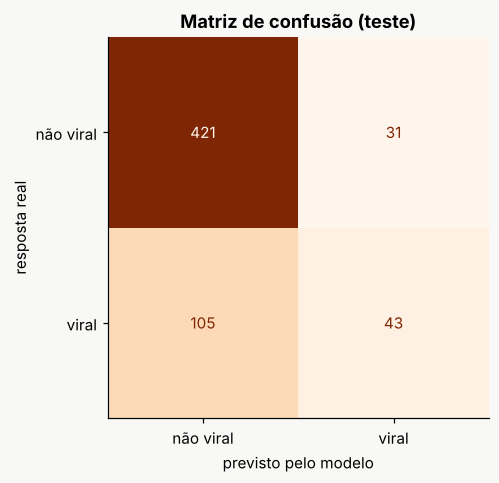

Verdadeiros negativos: 421   (não viral, e o modelo disse não)
Falsos positivos:      31   (alarme falso)
Falsos negativos:      105   (viral que o modelo deixou passar)
Verdadeiros positivos: 43   (viral, e o modelo acertou)


In [16]:
matriz = confusion_matrix(y_teste, prev)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(matriz, display_labels=["não viral", "viral"]).plot(ax=ax, cmap="Oranges", colorbar=False)
ax.set_xlabel("previsto pelo modelo"); ax.set_ylabel("resposta real"); ax.set_title("Matriz de confusão (teste)")
plt.show()

(vn, fp), (fn, vp) = matriz
print(f"Verdadeiros negativos: {vn}   (não viral, e o modelo disse não)")
print(f"Falsos positivos:      {fp}   (alarme falso)")
print(f"Falsos negativos:      {fn}   (viral que o modelo deixou passar)")
print(f"Verdadeiros positivos: {vp}   (viral, e o modelo acertou)")

| Métrica | Pergunta que responde |
|---|---|
| **Acurácia** | de todos os vídeos de teste, quantos % o modelo acertou? |
| **Precisão** | quando o modelo diz "viral", quantas vezes está certo? |
| **Recall** | dos vídeos que viralizaram, quantos o modelo encontrou? |
| **AUC** | dado um viral e um não viral ao acaso, com que frequência o modelo dá nota maior ao viral? (0,5 = chute) |

### 9.1 Limiar de decisão
Por padrão o modelo diz "viral" quando a probabilidade passa de 50%. Baixar esse limiar encontra mais virais (recall maior) com mais alarmes falsos (precisão menor):

In [17]:
linhas = []
for limiar in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (prob >= limiar).astype(int)
    linhas.append({"limiar": f"{limiar:.0%}", "acurácia": accuracy_score(y_teste, p),
                   "precisão": precision_score(y_teste, p, zero_division=0), "recall": recall_score(y_teste, p)})
pd.DataFrame(linhas).set_index("limiar").style.format("{:.1%}")

,acurácia,precisão,recall
limiar,,,
20%,64.8%,40.3%,88.5%
30%,73.3%,47.1%,66.9%
40%,75.5%,50.4%,44.6%
50%,77.3%,58.1%,29.1%
60%,76.5%,60.6%,13.5%


### 9.2 Conferências
**Validação cruzada (5 partes):** o resultado não depende de uma divisão de sorte?
**Comparação:** um modelo mais complexo (Random Forest) seria melhor?

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
notas = cross_val_score(montar_pipeline(LogisticRegression(max_iter=1000)), X_treino, y_treino, cv=cv, scoring="accuracy")
print(f"Acurácia na validação cruzada: {notas.mean():.1%} ± {notas.std():.1%}   {np.round(notas, 3)}")

rf = montar_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED)).fit(X_treino, y_treino)
comparacao = pd.DataFrame({
    "Acurácia": [acuracia_base, acuracia, accuracy_score(y_teste, rf.predict(X_teste))],
    "AUC": [0.5, roc_auc_score(y_teste, prob), roc_auc_score(y_teste, rf.predict_proba(X_teste)[:, 1])],
}, index=["Dummy (sempre 'não')", "Regressão Logística", "Random Forest"]).round(3)
comparacao

Acurácia na validação cruzada: 77.4% ± 1.1%   [0.767 0.769 0.779 0.762 0.794]


,Acurácia,AUC
Dummy (sempre 'não'),0.753,0.500
Regressão Logística,0.773,0.800
Random Forest,0.768,0.794


A Regressão Logística fica no mesmo nível da Random Forest, com a vantagem de ser simples e explicável peso por peso. Ela é o modelo final.

<a id="p10"></a>
## Passo 10 — Testando com dados completamente novos

`data/posts_novos.json` tem 4 posts escritos à mão que **não fazem parte** dos 3.000. Eles não têm `views` nem `seguidores`, porque ainda não foram postados. É a situação real de uso.

In [19]:
with open("../data/posts_novos.json", encoding="utf-8") as f:
    novos = json.load(f)

X_novos = pd.DataFrame([extrair(p) for p in novos])[vz.COLUNAS]
X_novos.insert(0, "id", [p["id"] for p in novos])
X_novos["chance_viral"] = pipeline.predict_proba(X_novos[vz.COLUNAS])[:, 1]
X_novos["previsao"] = np.where(X_novos.chance_viral >= 0.5, "VIRAL", "não viral")
X_novos.style.format({"chance_viral": "{:.1%}"})

,id,hook_segundos,tipo_hook,rosto_1s,texto_na_tela,duracao_seg,cortes_por_10s,estrutura,tem_loop,tema,audio_em_alta,hora_postagem,chance_viral,previsao
0,novo_01,0.600000,choque,1,1,21.000000,4.300000,antes_depois,1,humor,1,19,94.1%,VIRAL
1,novo_02,8.000000,nenhum,0,0,80.000000,0.800000,vlog,0,esporte,0,9,0.1%,não viral
2,novo_03,1.400000,promessa,1,1,35.000000,4.000000,tutorial,0,culinaria,0,12,63.4%,VIRAL
3,novo_04,3.200000,pergunta,0,1,30.000000,4.000000,lista,0,educacao,1,20,61.2%,VIRAL


<a id="p11"></a>
## Passo 11 — Exportando o modelo em `.pkl`

`pickle` transforma o objeto Python (o Pipeline inteiro, com o preparo e os pesos aprendidos) em um arquivo. Salvamos também informações para quem for usar o modelo.

> O `.pkl` guarda uma referência a `viralidade.criar_features`. Quem abrir o arquivo precisa ter o módulo `viralidade.py` disponível, por isso ele fica junto do app.

In [20]:
import sklearn
os.makedirs("../modelo", exist_ok=True)
pacote = {
    "nome": "Previsor de Viralidade — Regressão Logística",
    "autor": "Gustavo Pugliezi",
    "pipeline": pipeline,
    "colunas": vz.COLUNAS,
    "limiar": 0.5,
    "n_treino": len(X_treino),
    "acuracia_teste": float(acuracia),
    "versao_sklearn": sklearn.__version__,
}
with open("../modelo/previsor_viral.pkl", "wb") as f:
    pickle.dump(pacote, f)
print(f"Salvo em modelo/previsor_viral.pkl  ({os.path.getsize('../modelo/previsor_viral.pkl') / 1024:.1f} KB)")

Salvo em modelo/previsor_viral.pkl  (3.5 KB)


<a id="p12"></a>
## Passo 12 — Abrindo e rodando em outra aplicação

### 12.1 Carregando o `.pkl` do zero
Simulamos outro programa: abrimos o arquivo e conferimos que as previsões são idênticas às do modelo original.

In [21]:
with open("../modelo/previsor_viral.pkl", "rb") as f:
    carregado = pickle.load(f)

prob_carregado = carregado["pipeline"].predict_proba(X_teste)[:, 1]
assert np.allclose(prob_carregado, prob)
print(f"{carregado['nome']} | autor: {carregado['autor']} | acurácia: {carregado['acuracia_teste']:.1%}")
print("Previsões idênticas às do modelo original ✔")

Previsor de Viralidade — Regressão Logística | autor: Gustavo Pugliezi | acurácia: 77.3%
Previsões idênticas às do modelo original ✔


### 12.2 Aplicação de linha de comando
`app/prever.py` é um programa separado: lê um arquivo JSON de posts, extrai as features e usa o `.pkl` para prever. Funciona em qualquer terminal com Python:
```bash
cd app
python prever.py ../data/posts_novos.json
```

In [22]:
import prever
mostrar(prever.prever_posts)
!cd ../app && python prever.py ../data/posts_novos.json

def prever_posts(posts, pacote, usar_llm=False):
    extrair = vz.extrair_com_llm if usar_llm else vz.extrair_simulado
    feats = pd.DataFrame([extrair(p) for p in posts])[pacote["colunas"]]
    probs = pacote["pipeline"].predict_proba(feats)[:, 1]
    return [(p["id"], float(pr), int(pr >= pacote["limiar"])) for p, pr in zip(posts, probs)]

Modelo: Previsor de Viralidade — Regressão Logística (treinado com 2400 posts)



novo_01     94.1%  ███████████████████   VIRAL
novo_02      0.1%                        não viral
novo_03     63.4%  █████████████         VIRAL
novo_04     61.2%  ████████████          VIRAL


### 12.3 Site
O site em `site/index.html` usa os mesmos pesos, exportados abaixo para JavaScript, e permite montar um vídeo e ver a previsão na hora.

In [23]:
esc = pipeline.named_steps["preparo"].named_transformers_["num"]
ohe = pipeline.named_steps["preparo"].named_transformers_["cat"]
coef = dict(zip(nomes, lr.coef_[0]))
medias = dict(zip(nomes, pipeline[:-1].transform(X_treino).mean(axis=0)))
export = {
    "intercepto": float(lr.intercept_[0]),
    "numericas": {f: {"media": float(esc.mean_[i]), "desvio": float(esc.scale_[i]), "peso": float(coef[f"num__{f}"])}
                  for i, f in enumerate(vz.NUMERICAS)},
    "binarias": {f: {"peso": float(coef[f"bin__{f}"]), "media": float(medias[f"bin__{f}"])} for f in vz.BINARIAS},
    "categoricas": {f: {str(c): {"peso": float(coef[f"cat__{f}_{c}"]), "media": float(medias[f"cat__{f}_{c}"])} for c in cats}
                    for f, cats in zip(vz.CATEGORICAS, ohe.categories_)},
    "metricas": {"Acurácia": float(acuracia), "Precisão": float(precision_score(y_teste, prev)),
                 "Recall": float(recall_score(y_teste, prev)), "AUC": float(roc_auc_score(y_teste, prob))},
    "comparacao": {n: {k: float(v) for k, v in r.items()} for n, r in comparacao.iterrows()},
    "matriz": matriz.tolist(),
    "dados": {"total": len(dataset), "treino": len(X_treino), "teste": len(X_teste), "taxa_viral": float(taxa)},
}
with open("../site/model.js", "w", encoding="utf-8") as f:
    f.write("// Gerado pelo notebook (passo 12.3). Não edite à mão.\nwindow.MODELO = " + json.dumps(export, ensure_ascii=False, indent=1) + ";\n")
print("Pesos exportados para site/model.js")

Pesos exportados para site/model.js


---
## Conclusão

| | |
|---|---|
| **Problema** | prever se um vídeo curto viraliza (views ≥ 10× seguidores) |
| **Dados** | 3.000 posts em JSON → 11 features extraídas → dataset |
| **Modelo** | Regressão Logística em um Pipeline com engenharia de features |
| **Resultado** | ver passo 9: acurácia acima da linha de base e AUC ≈ 0,8 |
| **Entrega** | `modelo/previsor_viral.pkl`, usado por `app/prever.py` e pelo site |

### Limitações
1. **Dados simulados.** Para valer no mundo real, seria preciso anotar posts reais. O notebook funciona igual: basta trocar `posts.json`.
2. **Correlação não é causa.** Vídeos com loop viralizarem mais não prova que o loop é a causa.
3. **Fatores ausentes.** Algoritmo da plataforma, qualidade da ideia, tendências do momento. Por isso existe uma parte do resultado que é sorte e nenhum modelo prevê.
4. **Extração.** Um LLM pode errar a medição. Com dados reais, uma amostra deveria ser conferida por uma pessoa.